In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
data = pd.read_csv('fmcg_sales_3years_1M_rows.csv', parse_dates=['date'])
df =data
df.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [3]:
df.columns

Index(['date', 'year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend',
       'is_holiday', 'temperature', 'rain_mm', 'store_id', 'country', 'city',
       'channel', 'latitude', 'longitude', 'sku_id', 'sku_name', 'category',
       'subcategory', 'brand', 'units_sold', 'list_price', 'discount_pct',
       'promo_flag', 'gross_sales', 'net_sales', 'stock_on_hand',
       'stock_out_flag', 'lead_time_days', 'supplier_id', 'purchase_cost',
       'margin_pct'],
      dtype='object')

In [4]:
df.groupby('sku_id')['units_sold'].sum()

sku_id
SKU0001    1792381
SKU0002     766719
SKU0003     252376
SKU0004    1098948
SKU0005    1096500
            ...   
SKU0098     577352
SKU0099    1242389
SKU0100     920354
SKU0101     206503
SKU0102    1028846
Name: units_sold, Length: 102, dtype: int64

In [5]:
df.groupby(['category', 'subcategory'])['units_sold'].sum()

category       subcategory 
Beverages      Energy drink    4024789
               Juice           2731901
               Soda            6669099
               Water           4664597
Dairy          Cheese          3945244
               Milk            3230471
               Yogurt          3048487
Home Care      Cleaner         3565959
               Detergent       3269737
               Softener        2441514
Personal Care  Shampoo         2204139
               Soap            3768086
               Toothpaste      4827355
Snacks         Biscuits        3429968
               Chips           4350013
               Chocolate       4702964
               Nuts            4241659
Name: units_sold, dtype: int64

In [6]:
df['country'].unique()

array(['Germany', 'Italy', 'Poland', 'France', 'Spain', 'Austria',
       'Netherlands'], dtype=object)

In [7]:
country_dfs = dict(tuple(df.groupby('country')))
Germany_df = country_dfs['Germany']
Italy_df = country_dfs['Italy']
Poland_df = country_dfs['Poland']
France_df = country_dfs['France']
Spain_df = country_dfs['Spain']
Austria_df = country_dfs['Austria']
Netherlands_df = country_dfs['Netherlands']

### Germany_df

In [8]:
city_dfs = {}
for country, cdf in country_dfs.items():
    city_dfs[country] = dict(tuple(cdf.groupby('city')))

In [9]:
df['city'].unique()

array(['Berlin', 'Rome', 'Milan', 'Warsaw', 'Paris', 'Barcelona',
       'Vienna', 'Madrid', 'Amsterdam'], dtype=object)

In [10]:
Berlin = city_dfs['Germany']['Berlin']
Rome = city_dfs['Italy']['Rome']
Milan = city_dfs['Italy']['Milan']
Warsaw = city_dfs['Poland']['Warsaw']
Paris = city_dfs['France']['Paris']
Barcelona = city_dfs['Spain']['Barcelona']
Vienna = city_dfs['Austria']['Vienna']
Madrid = city_dfs['Spain']['Madrid']
Amsterdam = city_dfs['Netherlands']['Amsterdam']

In [11]:
Berlin.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [12]:
Rome.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
87600,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.3,1,1196.34,837.44,242,0,7,S043,5.13,0.155
87601,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,649.98,649.98,439,0,7,S001,5.69,0.396
87602,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.0,0,150.72,150.72,325,1,9,S051,4.70,0.501
87603,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.2,1,866.64,693.31,413,0,5,S015,6.00,0.163
87604,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.1,1,216.66,194.99,172,0,7,S054,4.85,0.386


In [13]:
store_dfs = {}
for country, cities in city_dfs.items():
    store_dfs[country] = {}
    for city, city_df in cities.items():
        store_dfs[country][city] = dict(tuple(city_df.groupby('store_id')))

In [14]:
df['store_id'].unique()

array(['STORE0001', 'STORE0002', 'STORE0003', 'STORE0004', 'STORE0005',
       'STORE0006', 'STORE0007', 'STORE0008', 'STORE0009', 'STORE0010',
       'STORE0011', 'STORE0012', 'STORE0013'], dtype=object)

In [15]:
Madrid['store_id'].unique()

array(['STORE0012'], dtype=object)

In [16]:
len(Amsterdam['sku_id'].unique())

45

In [17]:
def plot_dist(data):
    sns.set_theme(style='darkgrid')
    sns.lineplot(data=data, x='month', y='units_sold')
    
    plt.show()

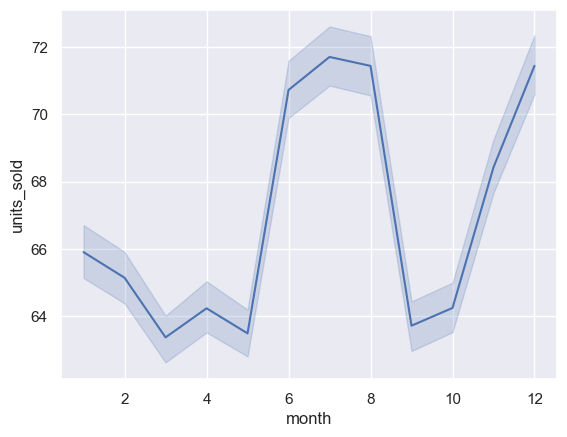

In [18]:
plot_dist(Berlin)

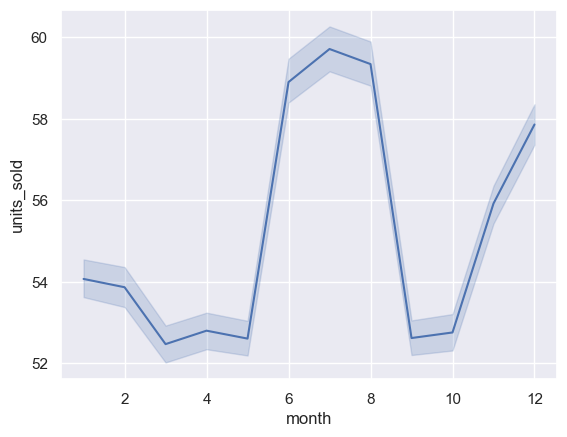

In [19]:
plot_dist(Italy_df)

<Axes: xlabel='date'>

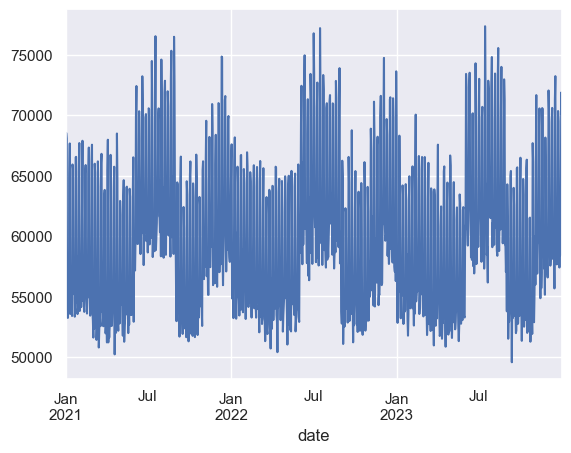

In [20]:
df.groupby("date")["units_sold"].sum().plot()

<Axes: xlabel='date'>

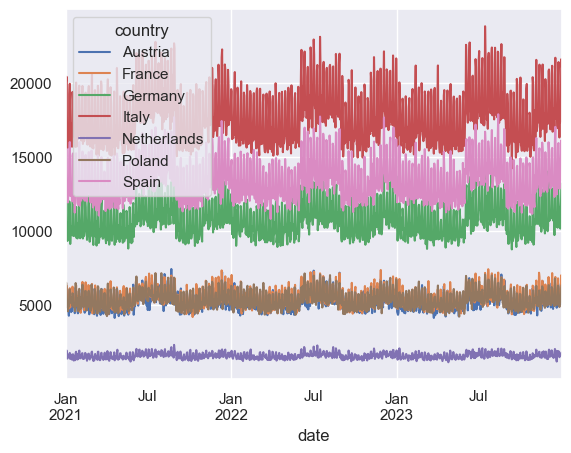

In [21]:
df.groupby(["date","country"])["units_sold"].sum().unstack().plot()

<Axes: xlabel='country'>

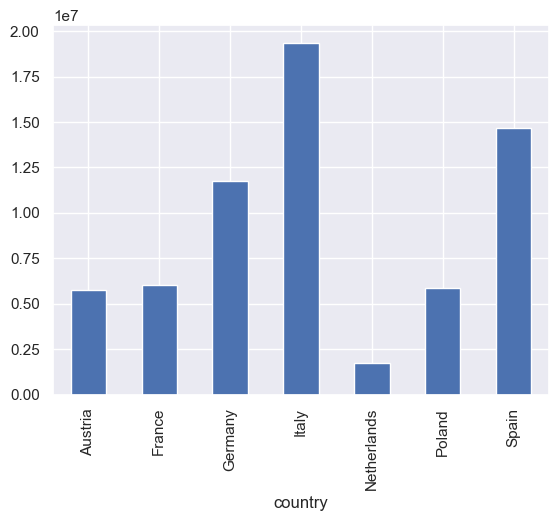

In [22]:
df.groupby("country")["units_sold"].sum().plot(kind="bar")

<Axes: ylabel='category'>

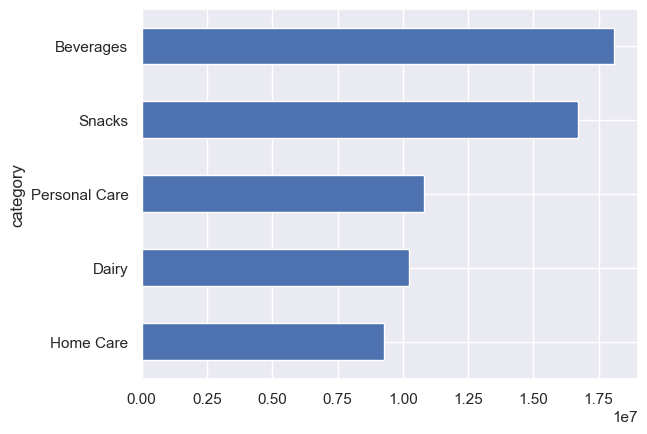

In [23]:
df.groupby("category")["units_sold"].sum().sort_values().plot(kind="barh")

<Axes: xlabel='brand'>

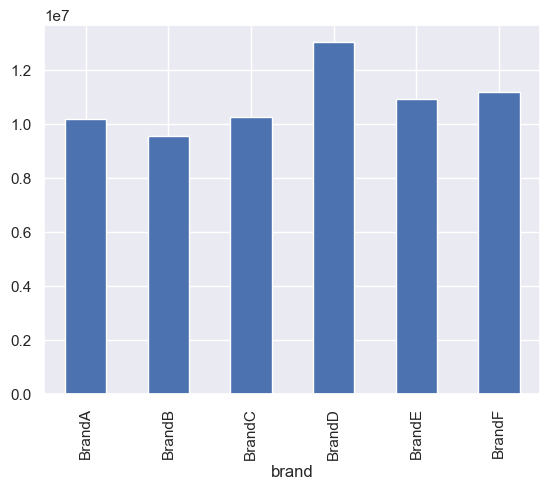

In [24]:
df.groupby("brand")["units_sold"].sum().plot(kind="bar")

<Axes: >

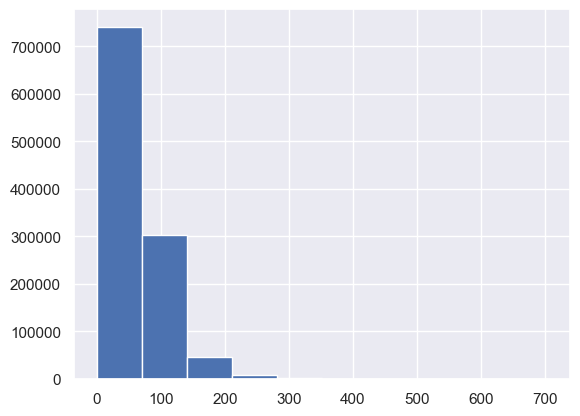

In [25]:
df["units_sold"].hist()

<Axes: title={'center': 'units_sold'}, xlabel='category'>

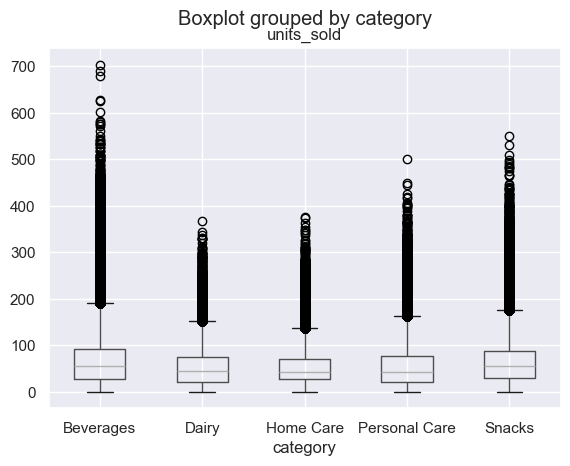

In [26]:
df.boxplot(column="units_sold", by="category")

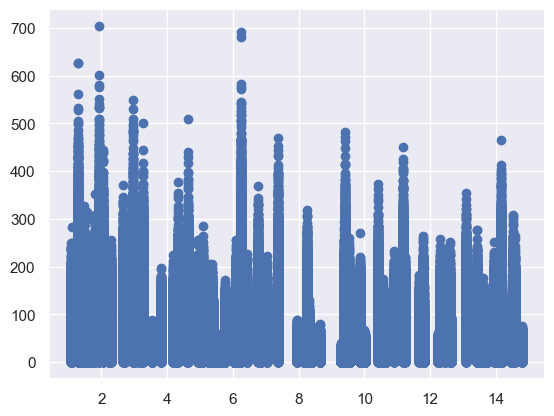

In [27]:
plt.scatter(df["list_price"], df["units_sold"])

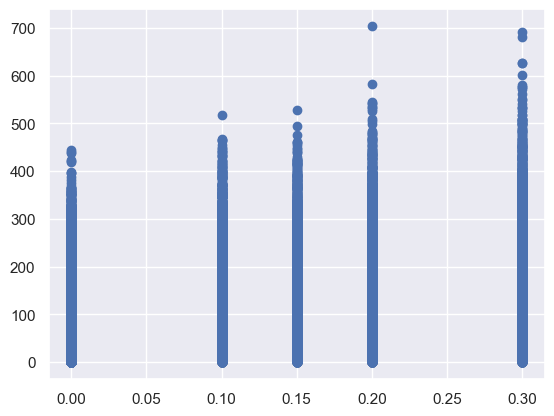

In [28]:
plt.scatter(df["discount_pct"], df["units_sold"])

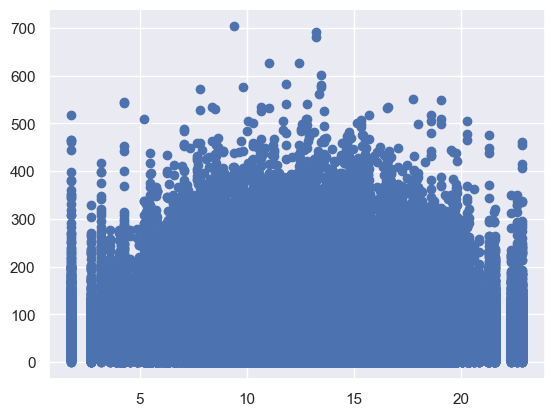

In [29]:
plt.scatter(df["temperature"], df["units_sold"])

<Axes: >

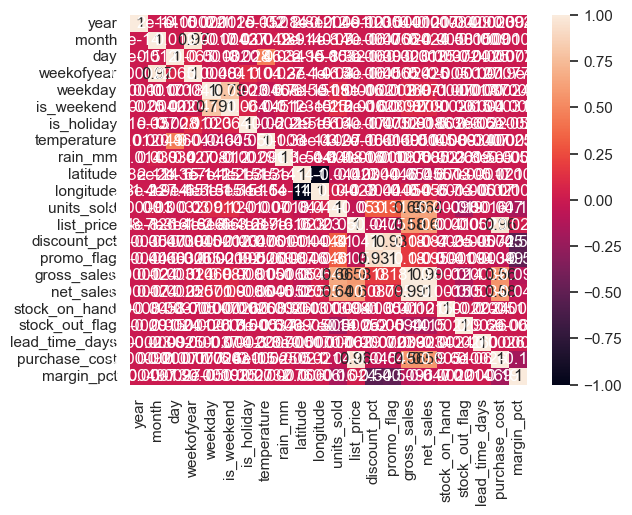

In [30]:
import seaborn as sns

sns.heatmap(Berlin.corr(numeric_only = True), annot=True)

<Axes: xlabel='promo_flag'>

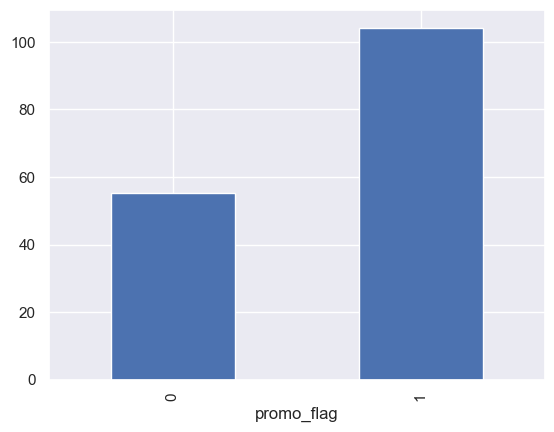

In [31]:
df.groupby("promo_flag")["units_sold"].mean().plot(kind="bar")

<Axes: xlabel='is_holiday'>

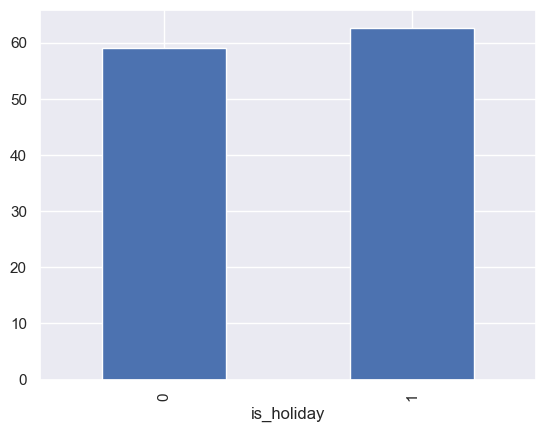

In [32]:
df.groupby("is_holiday")["units_sold"].mean().plot(kind="bar")

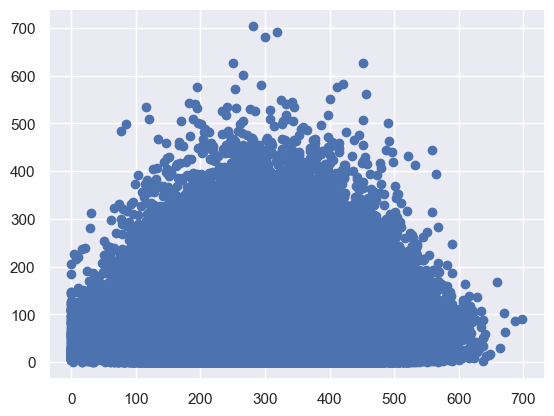

In [33]:
plt.scatter(df["stock_on_hand"], df["units_sold"])

<Axes: xlabel='stock_out_flag'>

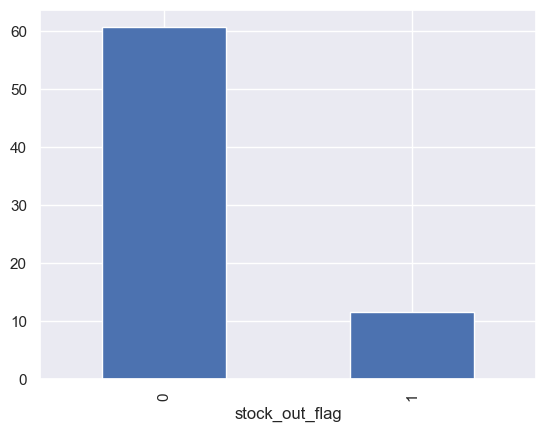

In [34]:
df.groupby("stock_out_flag")["units_sold"].mean().plot(kind="bar")

<Axes: xlabel='date'>

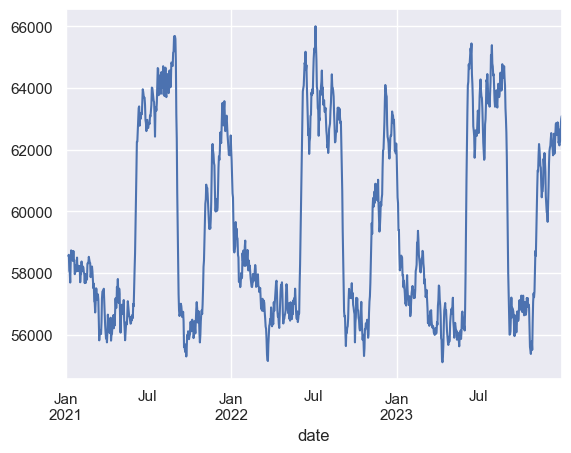

In [35]:
df.groupby("date")["units_sold"].sum().rolling(7).mean().plot()

###  Identify volatility (XYZ) by SKU

In [36]:
vol_ = df.groupby('sku_id')['units_sold'].agg(['mean', 'std'])

In [39]:
vol_['CV'] = vol_['mean'] / vol_['std']

In [40]:
vol_

,mean,std,CV
sku_id,,,
SKU0001,125.913664,68.857592,1.828610
SKU0002,70.020000,31.357488,2.232959
SKU0003,23.048037,10.478308,2.199595
SKU0004,100.360548,43.178090,2.324340
SKU0005,100.136986,54.526935,1.836468
...,...,...,...
SKU0098,47.932918,22.979753,2.085876
SKU0099,103.145621,54.014256,1.909600
SKU0100,84.050594,31.636620,2.656750


C:\Users\user\AppData\Local\Temp\ipykernel_8436\610702079.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data =vol_, x='sku_id', y='CV', palette='magma')


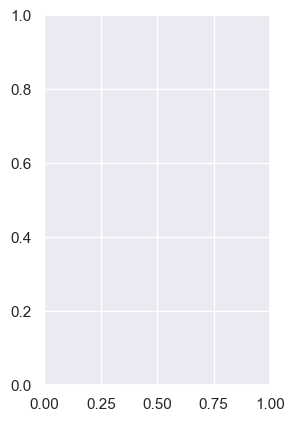

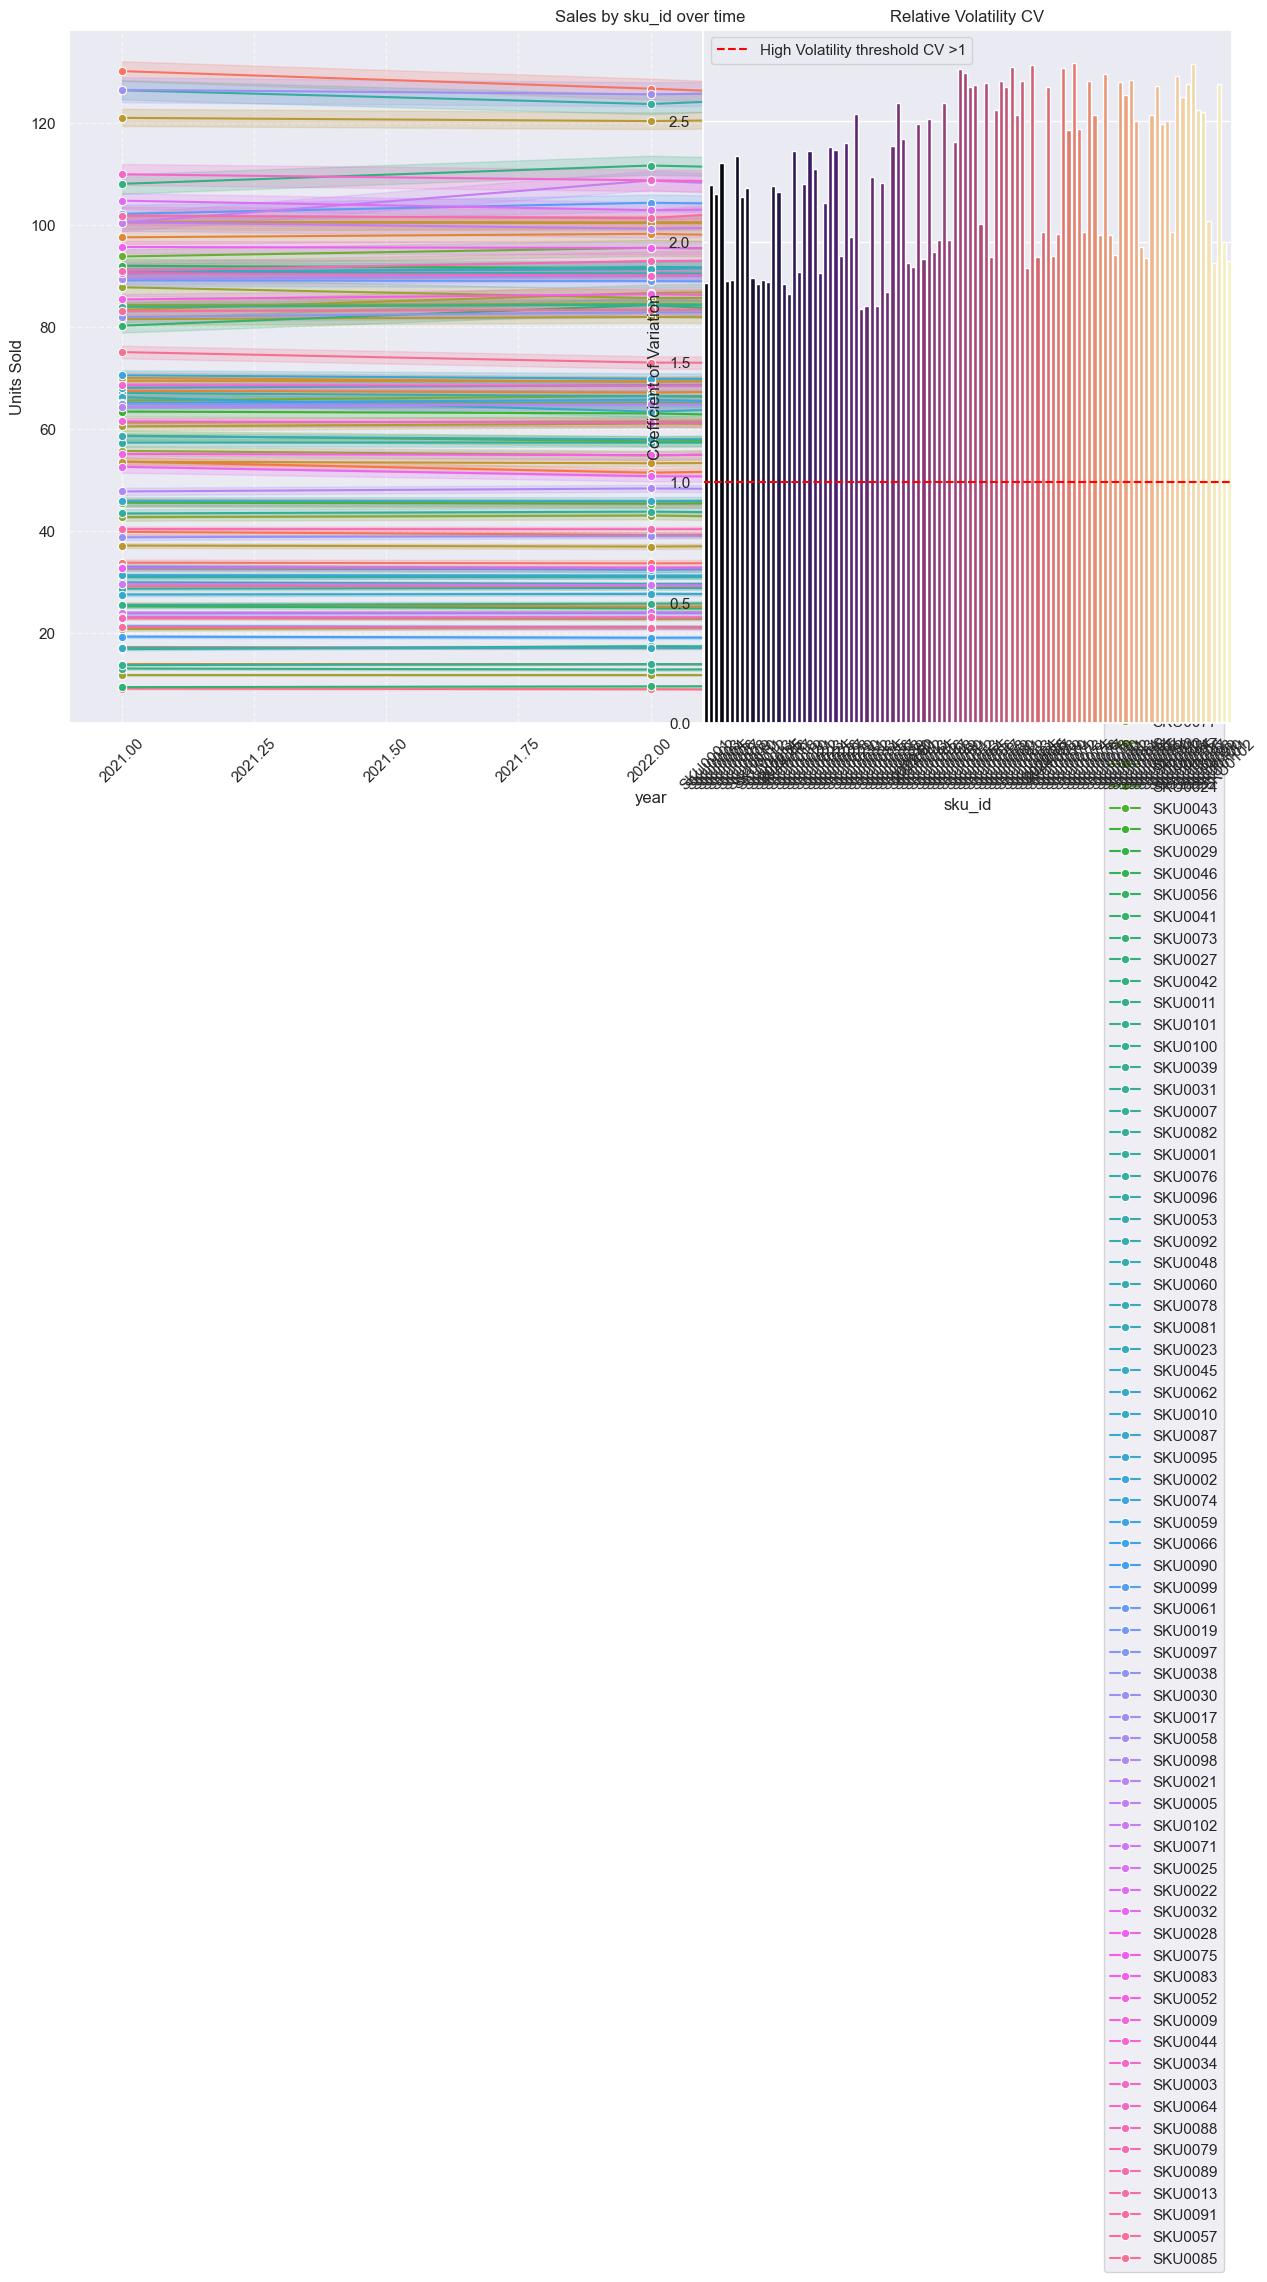

In [41]:
plt.subplot(1, 2, 1)
plt.figure(figsize=(15,9))
sns.lineplot(
    data = df, x= 'year', y='units_sold',
    hue = 'sku_id', marker = 'o')
plt.title('Sales by sku_id over time')
plt.ylabel('Units Sold')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
sns.barplot(data =vol_, x='sku_id', y='CV', palette='magma')
plt.axhline(1.0, color='red', linestyle='--', label='High Volatility threshold CV >1')
plt.title('Relative Volatility CV')
plt.ylabel('Coefficient of Variation')
plt.xticks(rotation=45)
plt.legend()

#plt.tight_layout()
plt.show()

In [42]:
yearly_sales = df.groupby('year')['units_sold'].sum()

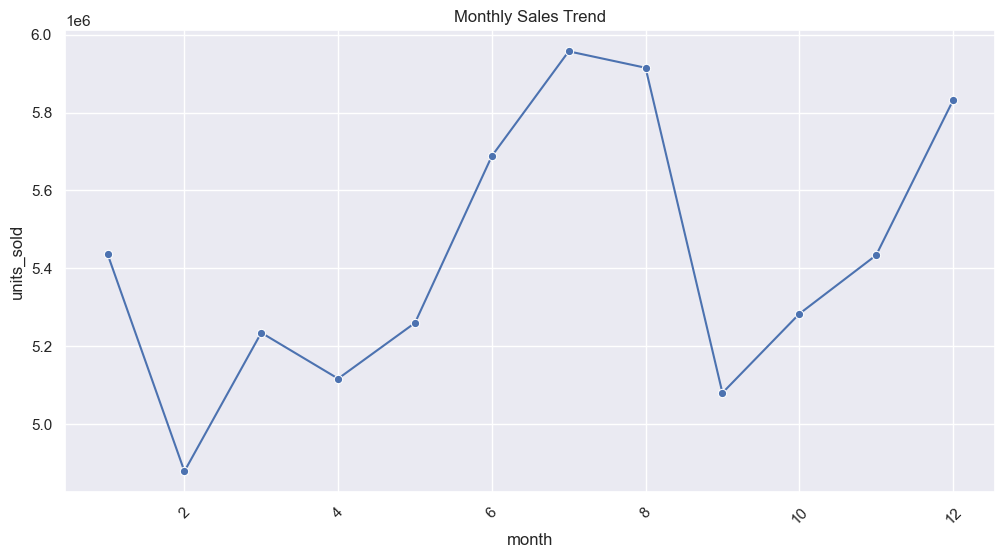

In [43]:
monthly_sales = df.groupby('month')['units_sold'].sum().reset_index()

plt.figure(figsize=(12,6))
sns.lineplot(data= monthly_sales, x='month', y='units_sold', marker='o')
plt.xticks(rotation=45)
plt.title('Monthly Sales Trend')
plt.show()

### Correlate Price, Promotions and Volume

In [44]:
corr = df[['net_sales', 'promo_flag','units_sold']].corr()

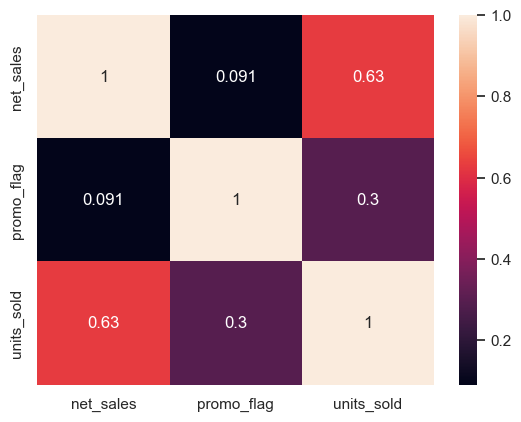

In [45]:
sns.heatmap(corr, annot=True)
plt.show()


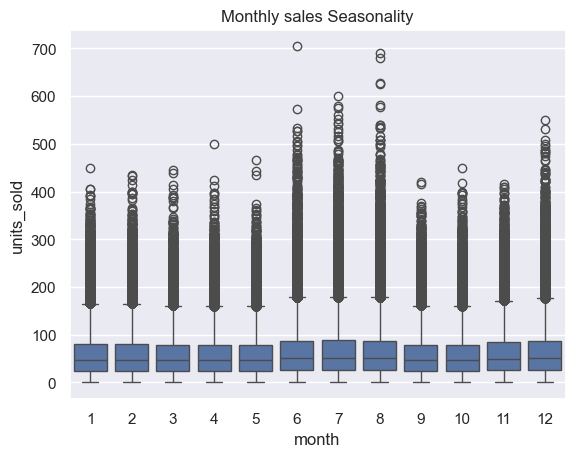

In [46]:
sns.boxplot(data=df, x='month', y='units_sold')
plt.title('Monthly sales Seasonality')
plt.show()

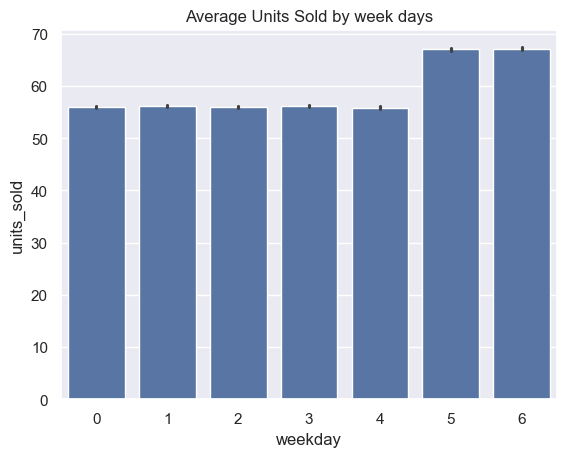

In [47]:
sns.barplot(data=df, x='weekday', y='units_sold')
plt.title('Average Units Sold by week days')
plt.show()

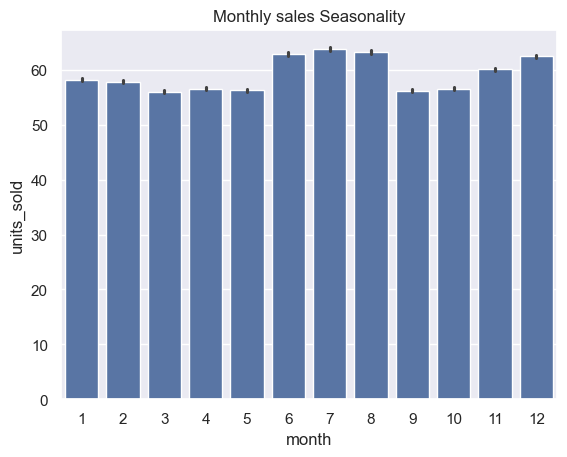

In [48]:
sns.barplot(data=df, x='month', y='units_sold')
plt.title('Monthly sales Seasonality')
plt.show()

In [49]:
from statsmodels.formula.api import ols
mdl_product_vs_sold = ols('units_sold ~ sku_id', data=df)

mdl_product_vs_sold = mdl_product_vs_sold.fit()
print(mdl_product_vs_sold.params)

Intercept            125.913664
sku_id[T.SKU0002]    -55.893664
sku_id[T.SKU0003]   -102.865627
sku_id[T.SKU0004]    -25.553116
sku_id[T.SKU0005]    -25.776677
                        ...    
sku_id[T.SKU0098]    -77.980745
sku_id[T.SKU0099]    -22.768043
sku_id[T.SKU0100]    -41.863070
sku_id[T.SKU0101]   -108.769371
sku_id[T.SKU0102]    -21.515287
Length: 102, dtype: float64


In [50]:
from statsmodels.formula.api import ols

# Example: Impact of the top 3 discovered factors
formula = 'units_sold ~ list_price + purchase_cost + discount_pct + promo_flag \
            + is_holiday + rain_mm + temperature + sku_name + channel + country +\
            net_sales'
model = ols(formula, data=df).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:             units_sold   R-squared:                       0.863
Model:                            OLS   Adj. R-squared:                  0.863
Method:                 Least Squares   F-statistic:                 5.980e+04
Date:                Wed, 01 Apr 2026   Prob (F-statistic):               0.00
Time:                        00:42:49   Log-Likelihood:            -4.6545e+06
No. Observations:             1100000   AIC:                         9.309e+06
Df Residuals:                 1099883   BIC:                         9.311e+06
Df Model:                         116                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

In [51]:
col = ['year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend',
       'is_holiday', 'temperature', 'rain_mm', 'store_id', 'country', 'city',
       'channel', 'latitude', 'longitude', 'sku_id', 'sku_name', 'category',
       'subcategory', 'brand', 'units_sold', 'list_price', 'discount_pct',
       'promo_flag', 'gross_sales', 'net_sales', 'stock_on_hand',
       'stock_out_flag', 'lead_time_days', 'supplier_id', 'purchase_cost',
       'margin_pct']

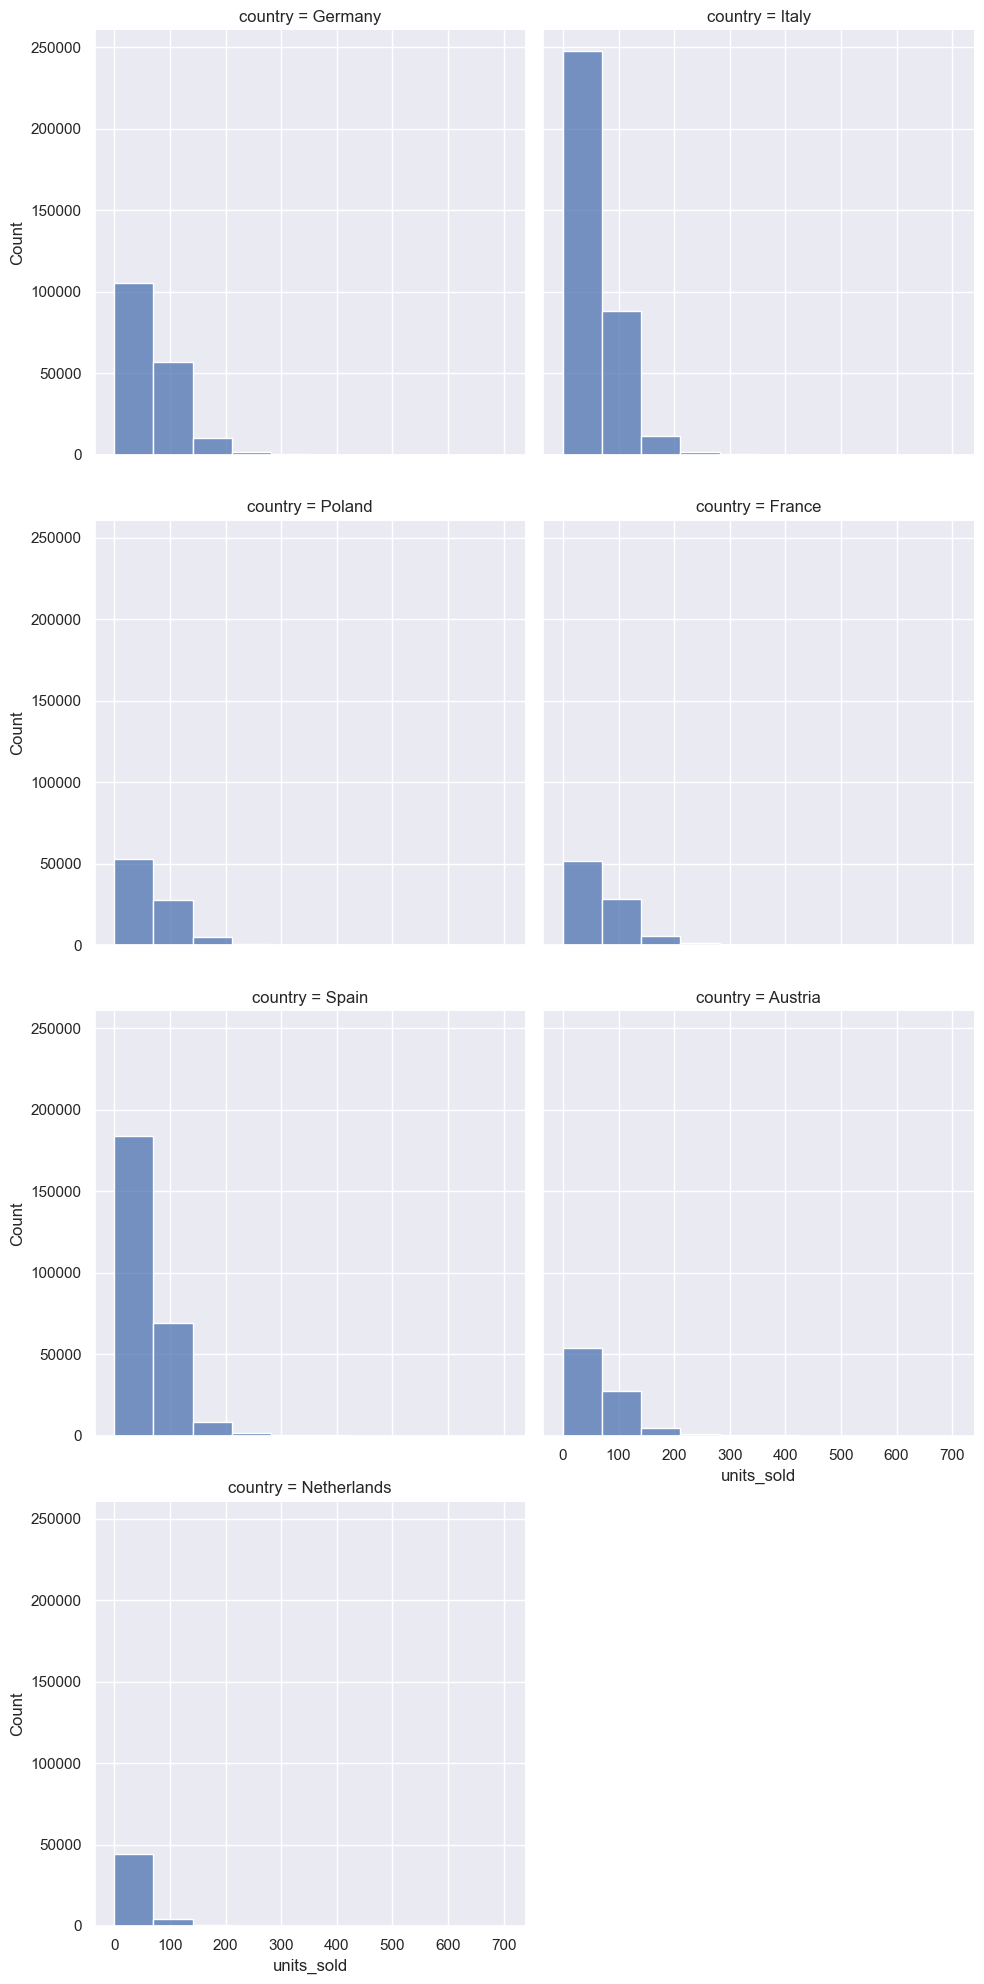

In [52]:
sns.displot(data=df,
           x='units_sold',
           col='country',
           col_wrap =2,
           bins=10)
plt.show()

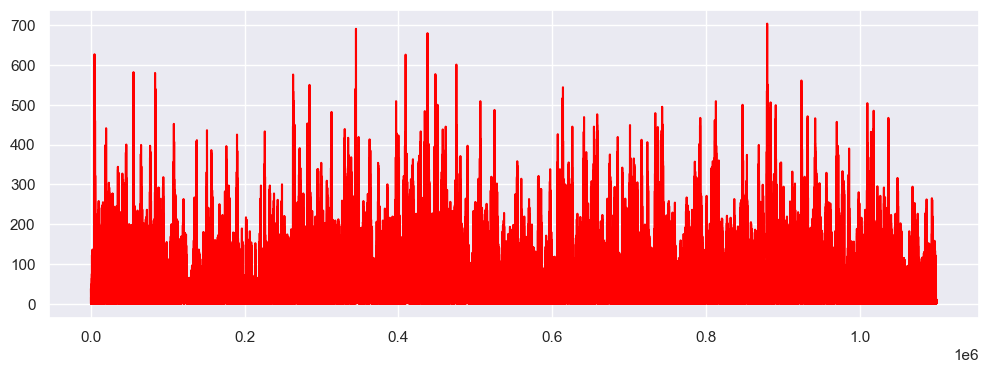

In [53]:
df['units_sold'].plot(color='red', figsize=(12,4))
plt.show()

In [54]:
from pyod.models.mad import MAD
mad = MAD().fit(df[['units_sold']])
is_outlier = mad.labels_ == 1
print(len(df[is_outlier]))

16921


In [57]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")

df['weekday']=df.index.day_of_week
df['month'] = df.index.month
df['day']= df.index.day

df.head()

,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,store_id,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,STORE0001,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,STORE0001,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,STORE0001,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,STORE0001,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,STORE0001,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [59]:
num_df = df.select_dtypes(include=["int64", "float64"])


In [60]:
from pyod.models.iforest import IForest

iforest = IForest().fit(num_df)

probs = iforest.predict_proba(num_df)

is_outlier = probs[:, 1] > 0.75
outliers = num_df[is_outlier]

print(len(outliers))

C:\Users\user\anaconda3\Lib\site-packages\sklearn\base.py:432: UserWarning: X has feature names, but IsolationForest was fitted without feature names
  warnings.warn(


5511


In [64]:
df_encoded = pd.get_dummies(df, columns=['store_id', 'country', 'city',
       'channel', 'sku_id', 'sku_name', 'category',
       'subcategory', 'brand','supplier_id'])

In [61]:
num_df.head()

,year,weekofyear,is_weekend,is_holiday,temperature,rain_mm,latitude,longitude,units_sold,list_price,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,purchase_cost,margin_pct
date,,,,,,,,,,,,,,,,,,,
2021-01-01,2021,53,0,1,8.44,1.24,52.52586,13.39071,16,10.49,0.1,1,167.84,151.06,248,0,11,7.53,0.182
2021-01-02,2021,53,1,0,12.61,1.12,52.52586,13.39071,12,10.49,0.0,0,125.88,125.88,238,0,6,5.19,0.505
2021-01-03,2021,53,1,0,12.02,2.69,52.52586,13.39071,38,10.49,0.3,1,398.62,279.03,238,0,6,5.59,0.168
2021-01-04,2021,1,0,0,7.76,4.65,52.52586,13.39071,8,10.49,0.0,0,83.92,83.92,216,0,7,7.81,0.255
2021-01-05,2021,1,0,0,11.16,1.77,52.52586,13.39071,17,10.49,0.2,1,178.33,142.66,372,0,8,7.62,0.073


In [63]:
df.columns

Index(['year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend',
       'is_holiday', 'temperature', 'rain_mm', 'store_id', 'country', 'city',
       'channel', 'latitude', 'longitude', 'sku_id', 'sku_name', 'category',
       'subcategory', 'brand', 'units_sold', 'list_price', 'discount_pct',
       'promo_flag', 'gross_sales', 'net_sales', 'stock_on_hand',
       'stock_out_flag', 'lead_time_days', 'supplier_id', 'purchase_cost',
       'margin_pct'],
      dtype='object')

In [65]:
df_encoded.head()

,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,latitude,...,supplier_id_S051,supplier_id_S052,supplier_id_S053,supplier_id_S054,supplier_id_S055,supplier_id_S056,supplier_id_S057,supplier_id_S058,supplier_id_S059,supplier_id_S060
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,52.52586,...,False,False,False,False,False,False,False,False,False,False
2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,52.52586,...,False,False,False,False,False,False,True,False,False,False
2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,52.52586,...,False,False,False,False,False,False,False,False,False,False
2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,52.52586,...,False,False,False,False,False,False,False,False,False,False
2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,52.52586,...,False,False,False,False,False,False,False,False,False,False


In [84]:
features = ['year', 'month', 'weekday', 'is_weekend', 'is_holiday',
            'temperature', 'rain_mm',
            'list_price', 'discount_pct', 'promo_flag',
            'stock_on_hand', 'stock_out_flag',
            'lead_time_days','purchase_cost']

X = df[features]

#iforest = IForest(contamination=0.01)
#df["anomaly"] = iforest.fit_predict(X)

In [85]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error as MSE

# Set seed for reproducibility
SEED = 1
y = df['units_sold']

# Split dataset into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = SEED
)

#Instantiate a GBRegressr gbt
gbt = GradientBoostingRegressor(n_estimators=30, max_depth=1, random_state=SEED)

#Fit gbt to training set
gbt.fit(X_train, y_train)

# Predict the set labels
y_pred = gbt.predict(X_test)

#Evaluate the test set RMSE
rmse_test = MSE(y_test, y_pred) ** (1/2)

#Print the tet set RMSE
print("Test set RMSE: {: .2f}".format(rmse_test))

Test set RMSE:  41.46


In [86]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
import xgboost as xgb

In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [88]:
# Initialize XGBoost model
model = xgb.XGBRegressor(
    n_estimators=100,   # number of trees
    learning_rate=0.1,  # step size shrinkage
    max_depth=3,        # maximum depth of a tree
    subsample=0.8,      # stochastic gradient boosting
    colsample_bytree=0.8, # fraction of features per tree
    random_state=42
)

In [89]:
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [90]:
y_pred = model.predict(X_test)
y_pred

array([39.482925, 59.815327, 29.810612, ..., 72.622574, 74.9922  ,
       48.175293], dtype=float32)

In [91]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2 Score: {r2:.4f}")

RMSE: 32.1903
MAE: 23.5892
R2 Score: 0.4910


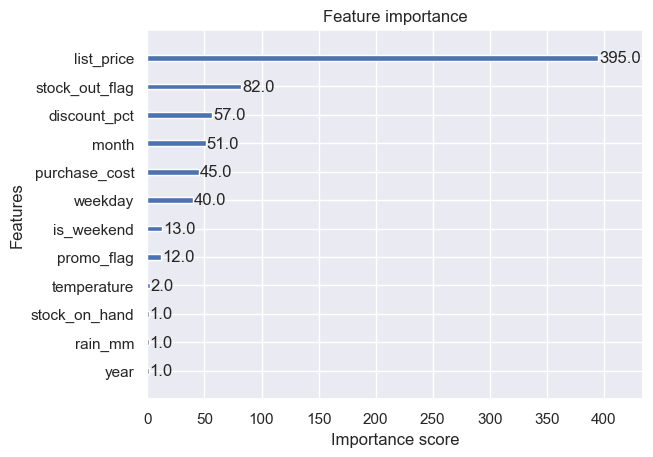

In [92]:
import matplotlib.pyplot as plt

xgb.plot_importance(model)
plt.show()